**Tensor example**

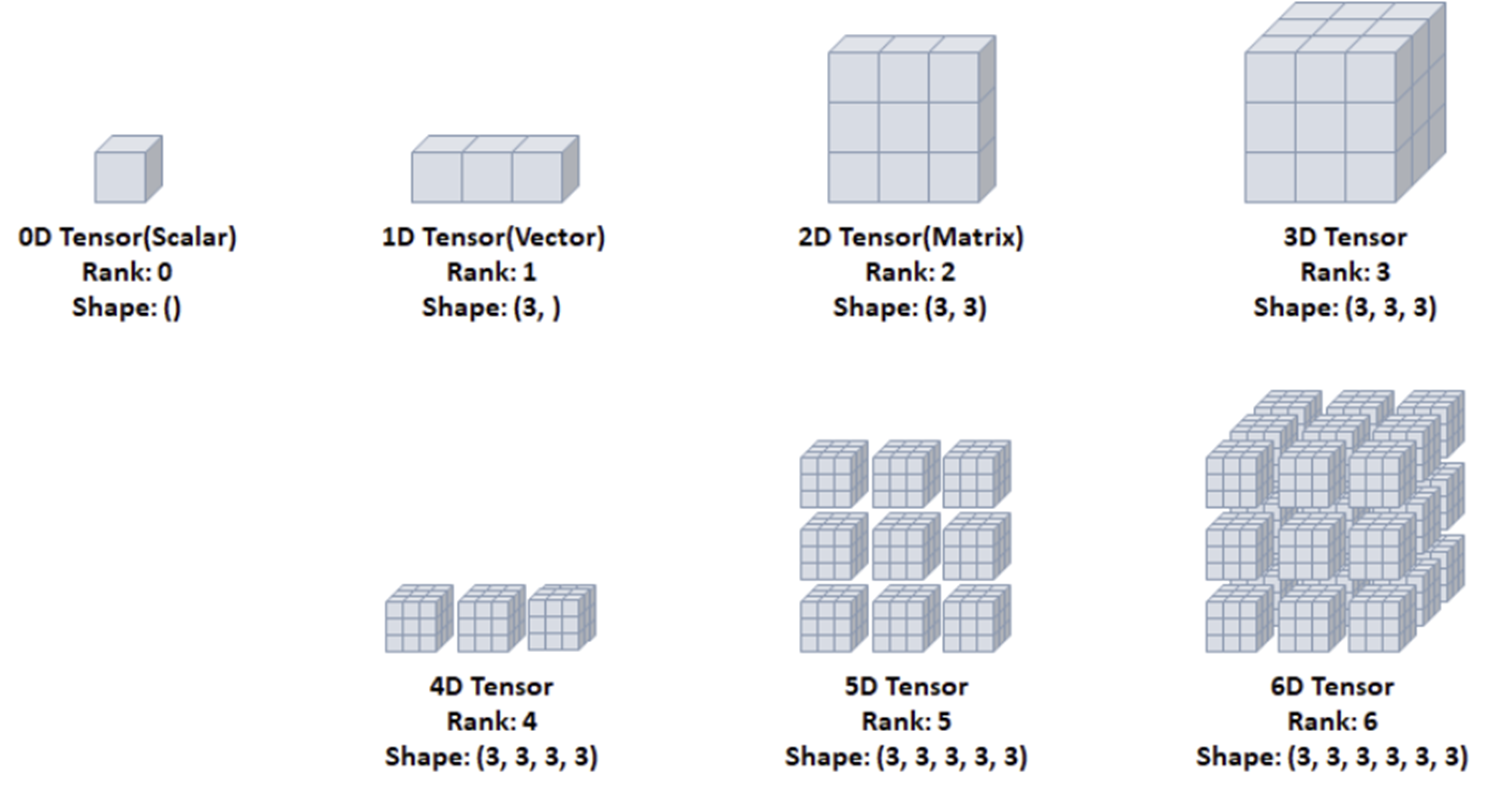

In [ ]:
import torch
torch.__version__

'2.10.0+cpu'

In [ ]:
x = torch.rand(3,2)
print(x)

tensor([[0.6576, 0.1949],
        [0.9610, 0.3006],
        [0.8073, 0.7200]])


In [ ]:
x = torch.zeros(3,2,dtype=torch.long)
print(x)

tensor([[0, 0],
        [0, 0],
        [0, 0]])


In [ ]:
x = torch.tensor([1,2,3])
print(x)

tensor([1, 2, 3])


In [ ]:
x = x.new_ones(3,2,dtype=torch.float64)
print(x)

tensor([[1., 1.],
        [1., 1.],
        [1., 1.]], dtype=torch.float64)


In [ ]:
print(x.size())

torch.Size([3, 2])


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [ ]:
tensor= torch.rand(1,3,3)
print(tensor)
print(tensor.shape)

tensor([[[0.0390, 0.9946, 0.8979],
         [0.4109, 0.0425, 0.7946],
         [0.4780, 0.3326, 0.5567]]])
torch.Size([1, 3, 3])


In [ ]:
t = tensor.squeeze()
print(t)
print(t.shape)

tensor([[0.0390, 0.9946, 0.8979],
        [0.4109, 0.0425, 0.7946],
        [0.4780, 0.3326, 0.5567]])
torch.Size([3, 3])


In [ ]:
t = torch.rand(3,3)
print(t)
print(t.shape)

tensor = t.unsqueeze(dim=0)
print(tensor)
print(tensor.shape)

tensor([[0.7509, 0.2299, 0.3096],
        [0.5131, 0.8663, 0.0691],
        [0.5800, 0.1318, 0.1334]])
torch.Size([3, 3])
tensor([[[0.7509, 0.2299, 0.3096],
         [0.5131, 0.8663, 0.0691],
         [0.5800, 0.1318, 0.1334]]])
torch.Size([1, 3, 3])


In [ ]:
a = torch.randn(1,3,3)
print(a)
print("=======================================")
b = torch.randn(1,3,3)
print(b)
print("=======================================")
c = torch.cat((a,b),dim=0)
print(c)


tensor([[[-1.3672e+00, -1.0712e-01,  1.7950e-04],
         [ 1.7748e-01, -8.1762e-01, -6.3957e-01],
         [-4.7688e-01, -1.9335e-01, -5.3679e-01]]])
tensor([[[-2.2005,  0.2987, -0.7917],
         [ 0.8362,  0.9912,  1.5640],
         [ 0.2134,  0.2405,  0.4921]]])
tensor([[[-1.3672e+00, -1.0712e-01,  1.7950e-04],
         [ 1.7748e-01, -8.1762e-01, -6.3957e-01],
         [-4.7688e-01, -1.9335e-01, -5.3679e-01]],

        [[-2.2005e+00,  2.9868e-01, -7.9165e-01],
         [ 8.3620e-01,  9.9118e-01,  1.5640e+00],
         [ 2.1342e-01,  2.4050e-01,  4.9213e-01]]])


**Simple Neural Network example**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


**Dataload**

In [ ]:
transform = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((0.5,),(0.5,))])

In [ ]:
trainset = datasets.FashionMNIST(root='/content',train=True, download=True,
                                 transform=transform)
testset = datasets.FashionMNIST(root='/content',train=False, download=True,
                                transform=transform)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.8MB/s]


In [ ]:
from torch.utils.data import DataLoader
train_loader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)

In [ ]:
images, labels = next(iter(train_loader))
images.shape, labels.shape

(torch.Size([128, 1, 28, 28]), torch.Size([128]))

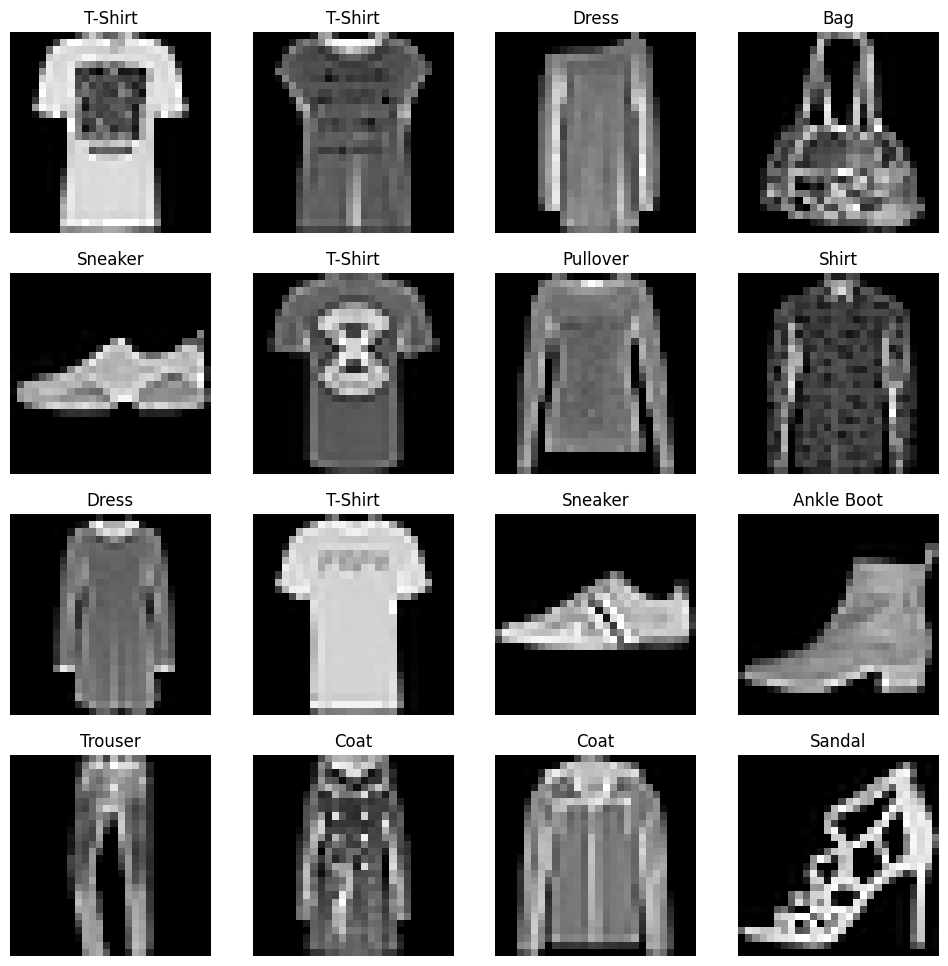

In [ ]:
from matplotlib import pyplot as plt
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot"
}

figure = plt.figure(figsize=(12,12))
cols, rows = 4,4
for i in range(1, cols * rows + 1):
  image = images[i].squeeze()
  label_idx = labels[i].item()
  label = labels_map[label_idx]

  figure.add_subplot(rows, cols, i)
  plt.title(label)
  plt.axis('off')
  plt.imshow(image, cmap='gray')
plt.show()

**Model implemenation**

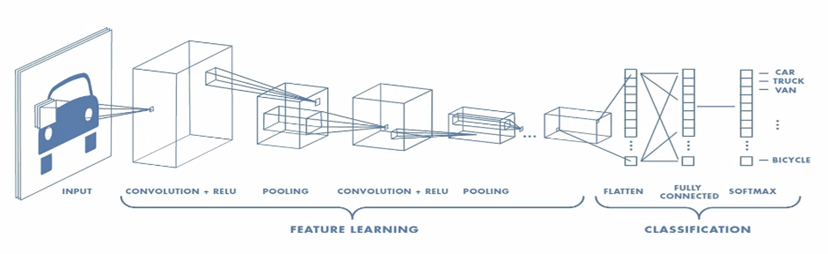

In [ ]:
class NN(nn.Module):
  def __init__(self):
    super(NN, self).__init__()

    self.conv1 = nn.Conv2d(1,6,3)
    self.conv2 = nn.Conv2d(6,16,3)
    self.fc1 = nn.Linear(16*5*5,120)
    self.fc2 = nn.Linear(120,84)
    self.fc3 = nn.Linear(84,10)

  def forward(self, x):
    x = F.max_pool2d(F.relu(self.conv1(x)), (2,2))
    x = F.max_pool2d(F.relu(self.conv2(x)), 2)
    x = x.view(-1, self.num_flat_features(x))
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

  def num_flat_features(self, x):
    size = x.size()[1:]
    num_features = 1
    for s in size:
      num_features *= s
    return num_features
net = NN()
print(net)


NN(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


**Loss function & Optimizer**

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

**Model training**

In [ ]:
total_batch = len(train_loader)
print(total_batch)

469


In [ ]:
for epoch in range(10):

  total_loss = 0.0

  for i, data in enumerate(train_loader, 0):
    inputs, labels = data

    optimizer.zero_grad()

    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    if i % 100 ==99:
      print(f'Epoch: {epoch+1}, Iter: {i+1}, Loss: {total_loss/100}')
      total_loss = 0.0

Epoch: 1, Iter: 100, Loss: 0.1146073418855667
Epoch: 1, Iter: 200, Loss: 0.11394639253616333
Epoch: 1, Iter: 300, Loss: 0.11263026857376099
Epoch: 1, Iter: 400, Loss: 0.10858122193813324
Epoch: 2, Iter: 100, Loss: 0.0682268512248993
Epoch: 2, Iter: 200, Loss: 0.04863247835636139
Epoch: 2, Iter: 300, Loss: 0.041179770499467847
Epoch: 2, Iter: 400, Loss: 0.0384248249232769
Epoch: 3, Iter: 100, Loss: 0.036170709311962125
Epoch: 3, Iter: 200, Loss: 0.03529351821541786
Epoch: 3, Iter: 300, Loss: 0.03450201408565044
Epoch: 3, Iter: 400, Loss: 0.034495349735021594
Epoch: 4, Iter: 100, Loss: 0.033384032189846036
Epoch: 4, Iter: 200, Loss: 0.03282581095397472
Epoch: 4, Iter: 300, Loss: 0.03254030831158161
Epoch: 4, Iter: 400, Loss: 0.03200763641297817
Epoch: 5, Iter: 100, Loss: 0.03173678201436996
Epoch: 5, Iter: 200, Loss: 0.03147265270352364
Epoch: 5, Iter: 300, Loss: 0.03076847203075886
Epoch: 5, Iter: 400, Loss: 0.030123842641711234
Epoch: 6, Iter: 100, Loss: 0.030311781600117684
Epoch: 6, 

**Model save & load**

In [ ]:
PATH = './fashion_mnist.pth'
torch.save(net.state_dict(), PATH)

In [ ]:
net = NN()
net.load_state_dict(torch.load(PATH))

<All keys matched successfully>

In [ ]:
net.parameters

<bound method Module.parameters of NN(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)>

**Model Test**

In [ ]:
import numpy as np
def imshow(image):
  image = image / 2 + 0.5
  npimg = image.numpy()

  fig = plt.figure(figsize=(16,8))
  plt.imshow(np.transpose(npimg, (1,2,0)))
  plt.show()

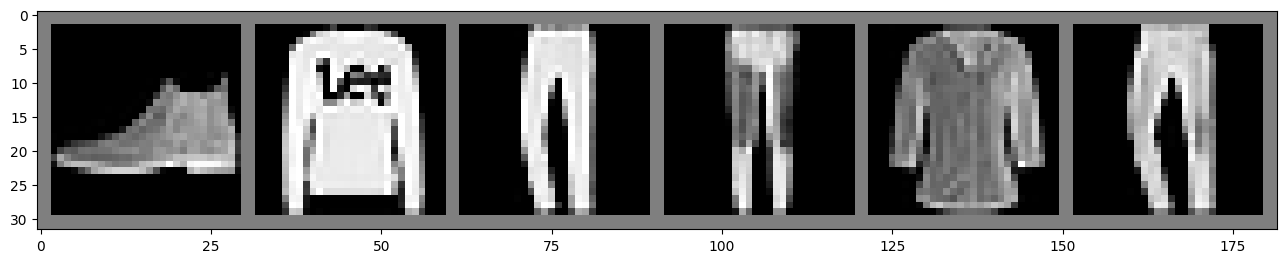

In [ ]:
import torchvision
import torchvision.utils
dataiter = iter(test_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:6]))

In [ ]:
outputs = net(images)
_, predicted = torch.max(outputs, 1)
print(predicted)

tensor([7, 2, 1, 1, 6, 1, 6, 6, 5, 7, 4, 5, 7, 3, 4, 1, 2, 6, 8, 0, 2, 7, 7, 5,
        1, 6, 6, 3, 9, 3, 8, 8, 3, 3, 8, 0, 7, 5, 7, 9, 0, 1, 6, 9, 6, 7, 2, 1,
        4, 6, 6, 6, 5, 6, 4, 2, 8, 6, 8, 0, 7, 7, 8, 5, 1, 1, 3, 4, 7, 8, 7, 0,
        2, 6, 4, 3, 1, 2, 8, 4, 1, 8, 5, 9, 5, 0, 3, 2, 0, 6, 5, 3, 6, 7, 1, 8,
        0, 1, 4, 2, 3, 4, 7, 6, 7, 8, 5, 7, 9, 4, 6, 5, 7, 0, 5, 2, 8, 4, 7, 8,
        0, 0, 9, 9, 3, 0, 8, 4])


In [ ]:
correct = 0
total = 0

with torch.no_grad():
  for data in test_loader:
    images, labels = data
    outputs = net(images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()


print(100 * correct / total)


79.67
